# 02 · CalMS21 Task 1 dataset guide

CalMS21 Task 1 contains 70 training videos (507,738 frames) of resident–intruder mouse interactions. Each frame has pose estimates, an expert behavior label, and aligned TREBA features. This notebook describes the training data; the official test set is reserved for final evaluation. Keep whole videos together when splitting because frames within a video are sequential.

In [ ]:
from collections import defaultdict
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "data/raw/task1_classic_classification/calms21_task1_train.json").is_file()
)
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / "notebooks"))

from notebooks._calms21 import BODY_PARTS, LABEL_NAMES, iter_training_videos
from src.data.preprocessing import get_video_arrays, iter_videos, valid_keypoints
from src.features import FEATURE_SETS, MOTION_FEATURES, SPATIAL_FEATURES, TREBA_FEATURES

RAW_DIR = ROOT / "data/raw"
TASK1_DIR = RAW_DIR / "task1_classic_classification"
TRAIN_PATH = TASK1_DIR / "calms21_task1_train.json"
TREBA_TRAIN_PATH = TASK1_DIR / "taskprog_features_task1_train.json"

print(f"Repository: {ROOT}")
print(f"Task 1 raw files: {TASK1_DIR}")

Repository: /Users/danielwu/Development/Repos/BME 522 Final Project
Task 1 raw files: /Users/danielwu/Development/Repos/BME 522 Final Project/data/raw/task1_classic_classification


## What is in `data/raw`?

For each split, `calms21_task1_*.json` contains MARS poses, tracking scores, labels, and metadata; `taskprog_features_task1_*.json` contains aligned 32-value TREBA features. This project develops on training files and reserves test data for final evaluation.

In [2]:
raw_files = []
for path in sorted(RAW_DIR.rglob("*")):
    if path.is_file():
        raw_files.append({
            "file": str(path.relative_to(ROOT)),
            "size_MB": path.stat().st_size / (1024 ** 2),
        })

display(pd.DataFrame(raw_files).style.format({"size_MB": "{:.1f}"}))

,file,size_MB
0,data/raw/calms21_convert_to_npy.py,0.0
1,data/raw/readme.md,0.0
2,data/raw/task1_classic_classification/calms21_task1_test.json,602.9
3,data/raw/task1_classic_classification/calms21_task1_train.json,1168.2
4,data/raw/task1_classic_classification/taskprog_features_task1_test.json,337.6
5,data/raw/task1_classic_classification/taskprog_features_task1_train.json,653.6
6,data/raw/task1_classic_classification.zip,436.2


## The JSON record and its axes

Each video record is grouped under `annotator-id_0` and contains **F** frames. Axes identify the resident/intruder, x/y coordinates, and seven keypoints (nose, ears, neck, hips, tail base); coordinates are pixels in 1024 × 570 images.

| Field | Raw JSON content | Shape for one video | Meaning |
|---|---|---:|---|
| `keypoints` | nested numeric lists | `(F, 2, 2, 7)` | x/y location of each of 7 tracked body parts for each mouse and frame |
| `scores` | nested numeric lists | `(F, 2, 7)` | confidence score for each tracked point, nominally from 0 to 1 |
| `annotations` | integer list | `(F,)` | one expert behavior label per frame |
| `metadata` | object/dictionary | not a frame array | annotator information and behavior-name-to-ID vocabulary |
| TREBA `features` | nested numeric lists | `(F, 32)` | learned per-frame representation from task programming; no individual feature has a simple pixel unit |

All frame arrays align by video ID and share F. `scores` describe keypoint tracking confidence; current pose models do not use them as predictors.

In [ ]:
# Inspect one training record
video_id, raw_video = next(iter_training_videos(TRAIN_PATH))
keypoints, scores, labels = get_video_arrays(raw_video, video_id)

schema_rows = []
for field in ("keypoints", "scores", "annotations", "metadata"):
    value = raw_video[field]
    array = np.asarray(value) if field != "metadata" else None
    schema_rows.append({
        "field": field,
        "raw Python type": type(value).__name__,
        "raw array shape": tuple(array.shape) if array is not None else "dictionary (not an array)",
        "converted NumPy dtype": {
            "keypoints": str(keypoints.dtype),
            "scores": str(scores.dtype),
            "annotations": str(labels.dtype),
        }.get(field, "—"),
    })

display(pd.DataFrame(schema_rows))
print(f"Example video ID: {video_id}")
print(f"Converted arrays: keypoints {keypoints.shape} {keypoints.dtype}; scores {scores.shape} {scores.dtype}; labels {labels.shape} {labels.dtype}")
print("Metadata vocabulary:", raw_video["metadata"]["vocab"])
print("Label names used by the project:", LABEL_NAMES)

,field,raw Python type,raw array shape,converted NumPy dtype
0,keypoints,list,"(21364, 2, 2, 7)",float32
1,scores,list,"(21364, 2, 7)",float32
2,annotations,list,"(21364,)",int64
3,metadata,dict,dictionary (not an array),—


Example video ID: task1/train/mouse001_task1_annotator1
Converted arrays: keypoints (21364, 2, 2, 7) float32; scores (21364, 2, 7) float32; labels (21364,) int64
Metadata vocabulary: {'attack': 0, 'investigation': 1, 'mount': 2, 'other': 3}
Label names used by the project: {0: 'attack', 1: 'investigation', 2: 'mount', 3: 'other'}


## Labels

Each frame has one expert label: attack, investigation, mount, or residual `other`. Named behaviors refer to actions initiated by the black resident mouse. Counts below are training frames, not independent behavior bouts or animals.

| ID | Label | Interpretation in this project |
|---:|---|---|
| 0 | `attack` | attack behavior |
| 1 | `investigation` | social investigation |
| 2 | `mount` | mounting behavior |
| 3 | `other` | all remaining annotated frames |

The class counts below use training annotations only.

In [4]:
video_rows = []
class_frames = np.zeros(len(LABEL_NAMES), dtype=np.int64)
class_confidence_sum = np.zeros(len(LABEL_NAMES), dtype=np.float64)
class_confidence_frames = np.zeros(len(LABEL_NAMES), dtype=np.int64)
all_low_confidence_points = 0
all_invalid_or_low_points = 0
all_points = 0
all_frames = 0

for current_video_id, payload in iter_training_videos(TRAIN_PATH):
    pose, point_scores, y = get_video_arrays(payload, current_video_id)
    frame_counts = np.bincount(y, minlength=len(LABEL_NAMES))
    frame_confidence = point_scores.mean(axis=(1, 2))
    valid_points = valid_keypoints(pose, point_scores, threshold=0.5)
    label_changes = np.flatnonzero(y[1:] != y[:-1])
    run_labels = y[np.r_[0, label_changes + 1]]

    video_row = {
        "video_id": current_video_id,
        "frames": len(y),
        "identity": current_video_id.split("/")[-1].split("_")[0],
        "label_runs": len(label_changes) + 1,
        "mean_point_confidence": float(point_scores.mean()),
        "points_below_0.5": float((point_scores < 0.5).mean()),
        "points_invalid_or_below_0.5": float((~valid_points).mean()),
    }
    for label_id, label_name in LABEL_NAMES.items():
        video_row[f"frames_{label_name}"] = int(frame_counts[label_id])
    video_rows.append(video_row)
    class_frames += frame_counts
    for label_id in LABEL_NAMES:
        mask = y == label_id
        class_confidence_sum[label_id] += frame_confidence[mask].sum()
        class_confidence_frames[label_id] += mask.sum()
    all_low_confidence_points += int((point_scores < 0.5).sum())
    all_invalid_or_low_points += int((~valid_points).sum())
    all_points += valid_points.size
    all_frames += len(y)

    del payload, pose, point_scores, y

video_table = pd.DataFrame(video_rows)
label_table = pd.DataFrame([
    {
        "ID": label_id,
        "label": label,
        "training frames": int(class_frames[label_id]),
        "share of training frames": class_frames[label_id] / class_frames.sum(),
        "videos containing label": int((video_table[f"frames_{label}"] > 0).sum()),
        "mean point confidence": class_confidence_sum[label_id] / class_confidence_frames[label_id],
    }
    for label_id, label in LABEL_NAMES.items()
])
print(f"Training videos: {len(video_table):,}")
print(f"Training frames: {all_frames:,}")
print(f"Distinct video identities: {video_table['identity'].nunique():,}")
print(f"Keypoints below confidence 0.5: {all_low_confidence_points / all_points:.2%}")
print(f"Keypoints invalid or below confidence 0.5: {all_invalid_or_low_points / all_points:.2%}")

Training videos: 70
Training frames: 507,738
Distinct video identities: 70
Keypoints below confidence 0.5: 12.18%
Keypoints invalid or below confidence 0.5: 12.18%


,ID,label,training frames,share of training frames,videos containing label,mean point confidence
0,0,attack,14039,2.77%,18,0.618
1,1,investigation,146615,28.88%,69,0.683
2,2,mount,28615,5.64%,41,0.625
3,3,other,318469,62.72%,70,0.694


,count,mean,std,min,25%,50%,75%,max
frames,70.0,7253.400000,5517.401453,96.000000,3032.000000,5568.000000,9826.500000,21364.000000
label_runs,70.0,57.214286,50.766557,2.000000,21.000000,43.000000,74.500000,290.000000
mean_point_confidence,70.0,0.669867,0.034742,0.582010,0.646620,0.666946,0.697054,0.740604
points_below_0.5,70.0,0.144191,0.067311,0.036114,0.081861,0.146217,0.199557,0.310268
points_invalid_or_below_0.5,70.0,0.144191,0.067311,0.036114,0.081861,0.146217,0.199557,0.310268


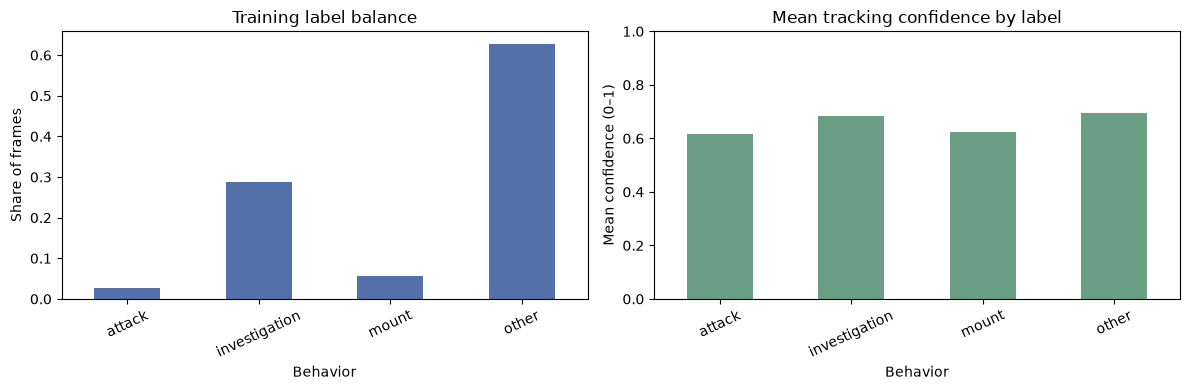

In [5]:
display(label_table.style.format({
    "share of training frames": "{:.2%}",
    "mean point confidence": "{:.3f}",
}))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
label_table.set_index("label")["share of training frames"].plot.bar(ax=axes[0], color="#5470a8")
axes[0].set(title="Training label balance", ylabel="Share of frames", xlabel="Behavior")
axes[0].tick_params(axis="x", rotation=25)
label_table.set_index("label")["mean point confidence"].plot.bar(ax=axes[1], color="#6a9f85", ylim=(0, 1))
axes[1].set(title="Mean tracking confidence by label", ylabel="Mean confidence (0–1)", xlabel="Behavior")
axes[1].tick_params(axis="x", rotation=25)
plt.tight_layout()

video_table[["frames", "label_runs", "mean_point_confidence", "points_below_0.5", "points_invalid_or_below_0.5"]].describe().T

## What are the model features?

`src/features/pose.py` derives six spatial and three frame-to-frame measurements per video. Motion is undefined for the first frame. TREBA is a separate 32-value representation; labels are targets, never input features.

## Derived pose features

| Feature | Definition | Units |
|---|---|---|
| `center_distance_px` | Euclidean distance between the mice's body centers | pixels |
| `nose_distance_px` | Euclidean distance between the two noses | pixels |
| `resident_body_length_px` | Resident nose-to-tail-base distance | pixels |
| `intruder_body_length_px` | Intruder nose-to-tail-base distance | pixels |
| `resident_orientation_to_intruder_cos` | Cosine between resident nose-facing axis and direction to intruder center | unitless, approximately [-1, 1] |
| `intruder_orientation_to_resident_cos` | Cosine between intruder nose-facing axis and direction to resident center | unitless, approximately [-1, 1] |
| `resident_speed_px_per_frame` | Resident body-center displacement from previous frame | pixels/frame |
| `intruder_speed_px_per_frame` | Intruder body-center displacement from previous frame | pixels/frame |
| `approach_rate_px_per_frame` | Decrease in center distance; positive means closer, negative means farther apart | pixels/frame |

## Feature sets

| Feature set | Dimensions per frame | Features |
|---|---:|---|
| `spatial` | 6 | `center_distance_px`, `nose_distance_px`, `resident_body_length_px`, `intruder_body_length_px`, `resident_orientation_to_intruder_cos`, `intruder_orientation_to_resident_cos` |
| `spatial_motion` | 9 | All six spatial features plus `resident_speed_px_per_frame`, `intruder_speed_px_per_frame`, `approach_rate_px_per_frame` |
| `treba` | 32 | Precomputed features `F01`–`F32` |

### How the pose measurements are calculated

Body centers average neck and hip keypoints; body orientation runs from tail base to nose. Distances and speed use image pixels, while orientation is a cosine score. Speed measures center displacement; approach rate is the previous minus current center distance. First-frame motion is `NaN`, and differences never cross video boundaries.

### TREBA representation

TREBA provides 32 learned values per frame from unlabeled CalMS21 trajectories. Its dimensions (`F01`–`F32`) have no simple physical meaning; `src/data/ingest.py` aligns them to labels by video ID and frame count.

In [7]:
# Inspect one raw TREBA training record and confirm its per-frame layout.
treba_video_id, treba_record = next(iter_videos(TREBA_TRAIN_PATH))
treba_array = np.asarray(treba_record["features"], dtype=np.float32)

print(f"TREBA example video ID: {treba_video_id}")
print(f"Raw feature field type: {type(treba_record['features']).__name__}")
print(f"Converted TREBA array: shape={treba_array.shape}, dtype={treba_array.dtype}")
print(f"Expected feature columns: {len(TREBA_FEATURES)} ({TREBA_FEATURES[0]} … {TREBA_FEATURES[-1]})")
print(f"One example row (first 5 dimensions): {treba_array[0, :5]}")

TREBA example video ID: task1/train/mouse001_task1_annotator1
Raw feature field type: list
Converted TREBA array: shape=(21364, 32), dtype=float32
Expected feature columns: 32 (F01 … F32)
One example row (first 5 dimensions): [-0.19556007 -0.22079001  0.22240743  0.22215754 -0.2368083 ]


## Dataset properties that matter for analysis

Frames within a video are related, and `other` dominates the labels. Keep videos intact when splitting and report macro/per-class F1. Tracking scores describe keypoint confidence; a score below 0.5 is diagnostic, not an exclusion rule. These summaries use training labels only, leaving the official test set for final evaluation.

## Where these values enter `src/`

`src/data/preprocessing.py` reads the raw arrays, `src/features/pose.py` derives pose features, and `src/data/ingest.py` applies the shared split and aligns TREBA. Imputation and scaling are fitted on training data.

## Sources

The local [CalMS21 release README](../data/raw/readme.md) documents the data format. See the [CalMS21 dataset paper](https://datasets-benchmarks-proceedings.neurips.cc/paper_files/paper/2021/hash/7f1de29e6da19d22b51c68001e7e0e54-Abstract-round1.html) and the [TREBA paper](https://openaccess.thecvf.com/content/CVPR2021/papers/Sun_Task_Programming_Learning_Data_Efficient_Behavior_Representations_CVPR_2021_paper.pdf) for background.